# TapaCheck — Inspección automática del roscado de tapas

**Start-up de Visión Artificial B2B · Entrega 3 · Visión Artificial (ITM)**

**El problema.** En una embotelladora, la roscadora pone y aprieta la tapa de cada botella. A veces la tapa queda floja, ladeada sobre la rosca, o la botella sale sin tapa. Ese producto se derrama, pierde el gas o se contamina, y el reclamo llega después desde el cliente. Hoy un operario mira la línea pasar, pero a miles de botellas por hora no puede revisar cada tapa con atención.

**La solución.** TapaCheck pone una cámara de lado frente al cuello de la botella, justo después de la roscadora, y clasifica cada tapa como **ROSCADA** o **MAL ROSCADA**. Usa solo **visión artificial clásica (sin Deep Learning)**, con el pipeline visto en clase:

1. **Extracción de características:** HOG (forma y bordes), LBP (micro-textura), GLCM (textura estadística) y su **fusión**.
2. **Normalización Z-score** (`StandardScaler`) y **reducción con PCA** del vector fusionado.
3. **Clasificación:** k-NN, SVM y Random Forest, comparados con métricas técnicas y de negocio.

**Dataset.** [bottle_cap_sdp](https://universe.roboflow.com/bottlecapproject-dyaxy/bottle_cap_sdp) de Roboflow Universe (proyecto *bottlecapproject*, licencia CC BY 4.0). Son 3.554 fotos reales del cuello de botellas PET, tomadas de lado entre el 29 de octubre y el 5 de noviembre de 2024, con la tapa de cada botella anotada. TapaCheck usa las cuatro clases que tienen que ver con el roscado:

| Clase del dataset | Qué muestra | Veredicto de TapaCheck |
|---|---|---|
| `good_cap` | Tapa roscada hasta el fondo | ROSCADA |
| `open_cap` | Tapa floja o levantada: la botella quedó abierta y se ve la rosca | MAL ROSCADA |
| `misplaced_cap` | Tapa ladeada o montada torcida sobre la rosca | MAL ROSCADA |
| `no_cap` | Botella sin tapa | MAL ROSCADA |

Las clases `damaged_cap` (tapa dañada) y `wet_cap` (tapa mojada) son otros defectos y quedan fuera de este producto.

**Cómo ejecutarlo.** En Roboflow se hace un *fork* del proyecto y se genera una versión con *Auto-Orient* y *Resize* a 640×640 (*Stretch*), **sin aumentación**. Esa versión se exporta en formato **YOLOv8** (unos 90 MB), se descomprime en la carpeta `data/` junto a este notebook y se ejecutan todas las celdas en orden (*Kernel → Restart & Run All*).

## 1. Librerías y configuración

In [1]:
import os
import glob
import time
import cv2
import yaml
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Descriptores de características (scikit-image)
from skimage.feature import hog, local_binary_pattern, graycomatrix, graycoprops

# Normalización, reducción y clasificadores (scikit-learn)
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

RUTA_DATOS = "data"            # carpeta donde se descomprime el .zip de Roboflow (formato YOLOv8)
CARPETA_FIGURAS = "figuras"    # aquí quedan las gráficas que se usan en el pitch
CARPETA_MODELOS = "modelos"
TAMANO = (128, 128)            # mismo tamaño de imagen usado en clase
MARGEN_ROI = 1.6               # el recorte fijo mide 1,6 veces el ancho típico de la tapa
SEMILLA = 42
CLASES = ['ROSCADA', 'MAL ROSCADA']   # 0: tapa bien roscada, 1: tapa mal roscada (clase positiva)

# Clase del dataset -> veredicto de TapaCheck. Las clases que no están aquí se descartan.
MAPA_CLASES = {'good_cap': 0, 'open_cap': 1, 'misplaced_cap': 1, 'no_cap': 1}
NOMBRE_TIPO = {'good_cap': 'Roscada', 'open_cap': 'Floja', 'misplaced_cap': 'Ladeada', 'no_cap': 'Sin tapa'}

os.makedirs(CARPETA_FIGURAS, exist_ok=True)
os.makedirs(CARPETA_MODELOS, exist_ok=True)
plt.rcParams['figure.dpi'] = 110

## 2. Carga de imágenes y recorte de la tapa (ROI)

Roboflow entrega el dataset ya partido en `train` (70 %), `valid` (20 %) y `test` (10 %). Cada foto trae un `.txt` con la clase y la caja de la tapa (formato YOLO, en coordenadas de 0 a 1).

- **Partición.** Esta versión no tiene aumentación, así que cada foto aparece una sola vez. Se entrena con `train` y se mide con `valid` + `test`, fotos que el modelo nunca ve.
- **Recorte fijo (ROI).** En la planta la cámara está fija y un sensor dispara la foto cuando el cuello pasa frente a ella, así que la tapa siempre cae en el mismo cuadro. Las fotos del dataset están encuadradas igual: el centro de la tapa se mueve apenas un 2 o 3 % del tamaño de la foto. Por eso TapaCheck recorta **siempre el mismo cuadrado**. Se calcula una sola vez con las cajas de `train`, como cuando se instala la cámara: centro mediano de la tapa y lado igual a 1,6 veces su ancho mediano. Para clasificar, el sistema recibe **solo la foto**: las anotaciones no se usan.
- Cada recorte pasa a escala de grises y a 128×128 px, como en clase.

In [2]:
extensiones = ('.jpg', '.jpeg', '.png', '.bmp')

def buscar_dataset(raiz):
    # Roboflow deja un data.yaml en la raíz del .zip descomprimido
    for actual, _, archivos in os.walk(raiz):
        if 'data.yaml' in archivos:
            return actual
    raise FileNotFoundError(f"No se encontró data.yaml dentro de '{raiz}/'. "
                            "Descomprima ahí el .zip de Roboflow en formato YOLOv8.")

def leer_nombres(carpeta):
    with open(os.path.join(carpeta, 'data.yaml'), encoding='utf-8') as f:
        nombres = yaml.safe_load(f)['names']
    return list(nombres.values()) if isinstance(nombres, dict) else list(nombres)

def leer_caja(linea):
    # Línea YOLO: clase cx cy w h (caja) o clase x1 y1 x2 y2 ... (polígono), todo de 0 a 1
    valores = linea.split()
    coords = np.array(valores[1:], dtype=float)
    if len(coords) == 4:
        cx, cy, w, h = coords
    else:
        xs, ys = coords[0::2], coords[1::2]
        cx, cy, w, h = (xs.min() + xs.max()) / 2, (ys.min() + ys.max()) / 2, xs.max() - xs.min(), ys.max() - ys.min()
    return int(valores[0]), cx, cy, w, h

def leer_etiquetas(carpeta_split, nombres):
    # Una fila por foto: ruta, tipo de tapa y caja anotada.
    # La caja solo se usa para calibrar el recorte fijo y para dibujar las figuras, nunca para predecir.
    filas = []
    for ruta in sorted(glob.glob(os.path.join(carpeta_split, 'images', '*'))):
        if not ruta.lower().endswith(extensiones):
            continue
        ruta_txt = os.path.join(carpeta_split, 'labels', os.path.splitext(os.path.basename(ruta))[0] + '.txt')
        if not os.path.exists(ruta_txt):
            continue
        with open(ruta_txt) as f:
            cajas = [leer_caja(l) for l in f.read().splitlines() if l.strip()]
        # Se descartan las fotos sin tapa anotada, con varias tapas o de clases fuera del alcance
        if len(cajas) != 1 or nombres[cajas[0][0]] not in MAPA_CLASES:
            continue
        clase, cx, cy, w, h = cajas[0]
        filas.append({'ruta': ruta, 'tipo': nombres[clase], 'cx': cx, 'cy': cy, 'w': w, 'h': h})
    return pd.DataFrame(filas)

def cuadro_roi(forma):
    # El mismo cuadrado en todas las fotos (cámara fija): centro y lado en fracciones de la foto
    alto, ancho = forma[:2]
    lado = int(round(ROI['lado'] * ancho))
    x0, y0 = int(round(ROI['cx'] * ancho - lado / 2)), int(round(ROI['cy'] * alto - lado / 2))
    return x0, y0, x0 + lado, y0 + lado

def recortar_tapa(gris):
    x0, y0, x1, y1 = cuadro_roi(gris.shape)
    borde = max(0, -x0, -y0, x1 - gris.shape[1], y1 - gris.shape[0])
    if borde:  # si el cuadrado se sale de la foto, se rellena repitiendo el borde
        gris = cv2.copyMakeBorder(gris, borde, borde, borde, borde, cv2.BORDER_REPLICATE)
        x0, y0, x1, y1 = x0 + borde, y0 + borde, x1 + borde, y1 + borde
    return cv2.resize(gris[y0:y1, x0:x1], TAMANO, interpolation=cv2.INTER_AREA)

def cargar_recortes(info):
    return np.array([recortar_tapa(cv2.imread(ruta, cv2.IMREAD_GRAYSCALE)) for ruta in info['ruta']])

t0 = time.time()
carpeta = buscar_dataset(RUTA_DATOS)
nombres = leer_nombres(carpeta)
info_train = leer_etiquetas(os.path.join(carpeta, 'train'), nombres)
info_test = pd.concat([leer_etiquetas(os.path.join(carpeta, s), nombres) for s in ['valid', 'test']], ignore_index=True)

# Calibración del recorte fijo, una sola vez y solo con train (como al instalar la cámara)
ROI = {'cx': info_train['cx'].median(), 'cy': info_train['cy'].median(), 'lado': MARGEN_ROI * info_train['w'].median()}
print(f"Clases del dataset: {nombres}")
print(f"Recorte fijo: centro ({ROI['cx']:.3f}, {ROI['cy']:.3f}) y lado {ROI['lado']:.3f} del ancho de la foto")
print(f"El centro de la tapa varía ±{info_train['cx'].std():.3f} en x y ±{info_train['cy'].std():.3f} en y (desviación estándar)")

X_train, X_test = cargar_recortes(info_train), cargar_recortes(info_test)
y_train = info_train['tipo'].map(MAPA_CLASES).to_numpy(dtype=int)
y_test = info_test['tipo'].map(MAPA_CLASES).to_numpy(dtype=int)
tipo_train, tipo_test = info_train['tipo'].to_numpy(), info_test['tipo'].to_numpy()
print(f"Dataset listo en {time.time() - t0:.1f} s -> Train: {X_train.shape}, Test: {X_test.shape}")

conteo = pd.DataFrame({'Train': info_train['tipo'].value_counts(), 'Test': info_test['tipo'].value_counts()})
conteo = conteo.reindex(list(MAPA_CLASES)).fillna(0).astype(int)
conteo.index = [f"{t} ({NOMBRE_TIPO[t]} -> {CLASES[MAPA_CLASES[t]]})" for t in conteo.index]
conteo.loc['Total'] = conteo.sum()
display(conteo)

Clases del dataset: ['damaged_cap', 'good_cap', 'misplaced_cap', 'no_cap', 'open_cap', 'wet_cap']
Recorte fijo: centro (0.513, 0.506) y lado 0.604 del ancho de la foto
El centro de la tapa varía ±0.019 en x y ±0.027 en y (desviación estándar)


Dataset listo en 4.7 s -> Train: (1994, 128, 128), Test: (855, 128, 128)


,Train,Test
good_cap (Roscada -> ROSCADA),1414,606
open_cap (Floja -> MAL ROSCADA),217,94
misplaced_cap (Ladeada -> MAL ROSCADA),174,74
no_cap (Sin tapa -> MAL ROSCADA),189,81
Total,1994,855


In [3]:
# Control de fuga de datos: ninguna foto original puede quedar a la vez en train y en test.
# Roboflow nombra cada copia <foto>_jpg.rf.<código>.jpg; lo que va antes de '.rf.' identifica la foto original.
def foto_original(ruta):
    return os.path.basename(ruta).split('.rf.')[0]

fotos_train = set(info_train['ruta'].map(foto_original))
fotos_test = set(info_test['ruta'].map(foto_original))
print(f"Fotos originales -> train: {len(fotos_train)}, test: {len(fotos_test)}, "
      f"repetidas entre train y test: {len(fotos_train & fotos_test)}")

Fotos originales -> train: 1994, test: 855, repetidas entre train y test: 0


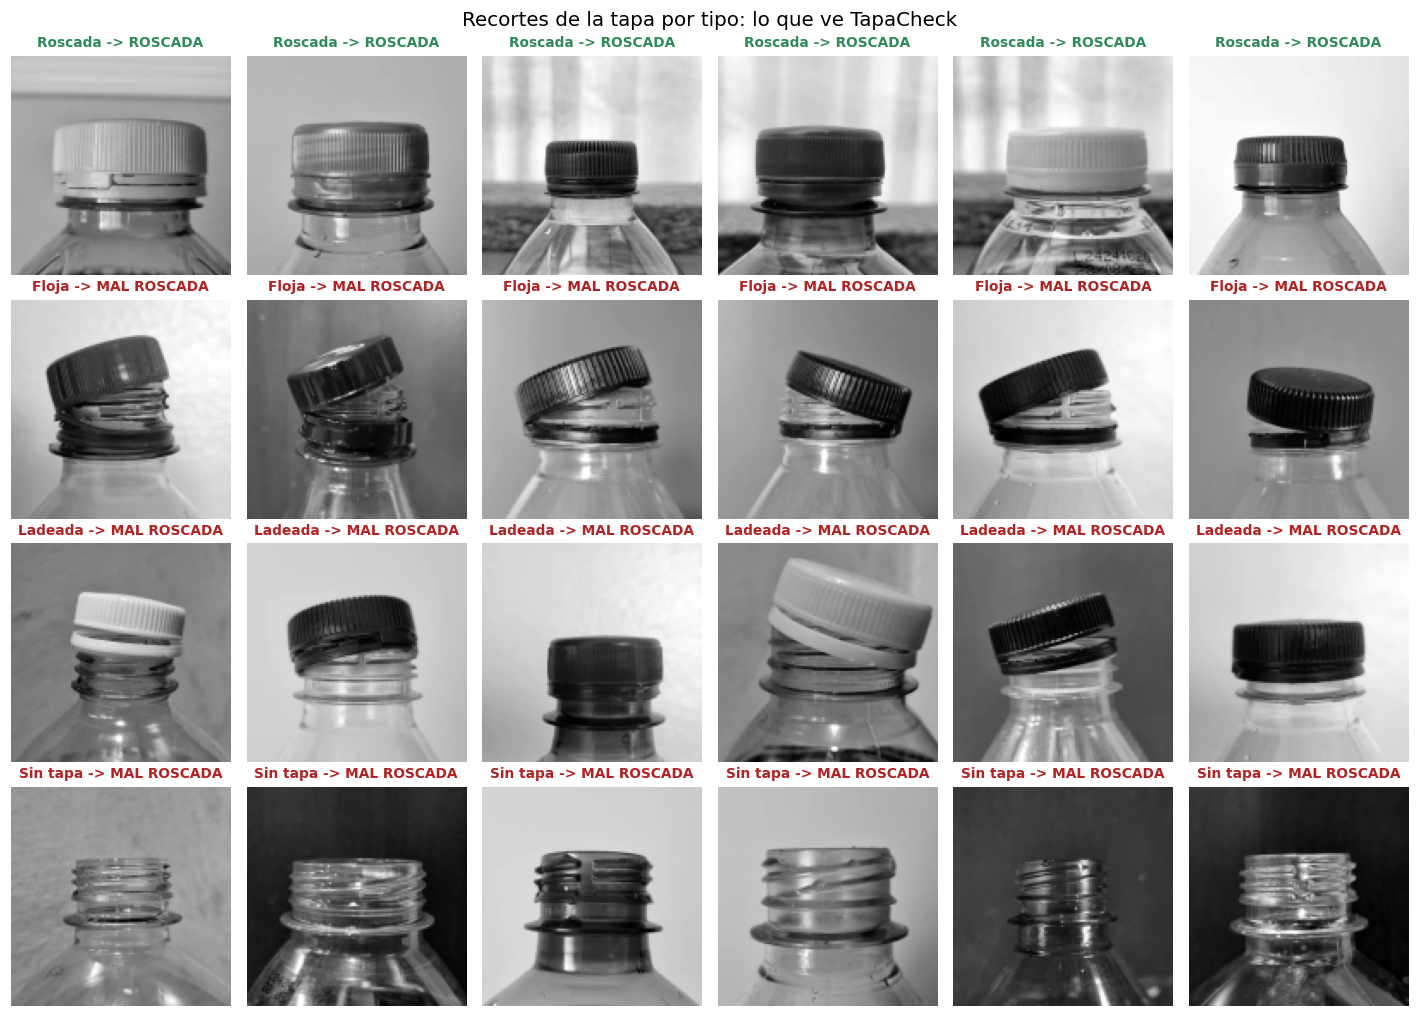

In [4]:
# Muestras de cada tipo de tapa (recortes de 128x128 que ve el clasificador)
tipos = [t for t in MAPA_CLASES if (tipo_train == t).any()]
fig, axes = plt.subplots(len(tipos), 6, figsize=(13, 2.35 * len(tipos)))
axes = np.atleast_2d(axes)
rng = np.random.default_rng(SEMILLA)
for fila, t in enumerate(tipos):
    idx = np.where(tipo_train == t)[0]
    elegidos = rng.choice(idx, min(6, len(idx)), replace=False)
    for col in range(6):
        ax = axes[fila, col]
        ax.axis('off')
        if col < len(elegidos):
            ax.imshow(X_train[elegidos[col]], cmap='gray')
            ax.set_title(f"{NOMBRE_TIPO[t]} -> {CLASES[MAPA_CLASES[t]]}", fontsize=9, fontweight='bold',
                         color='seagreen' if MAPA_CLASES[t] == 0 else 'firebrick')
plt.suptitle("Recortes de la tapa por tipo: lo que ve TapaCheck", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_FIGURAS, "muestras.png"), bbox_inches='tight')
plt.show()

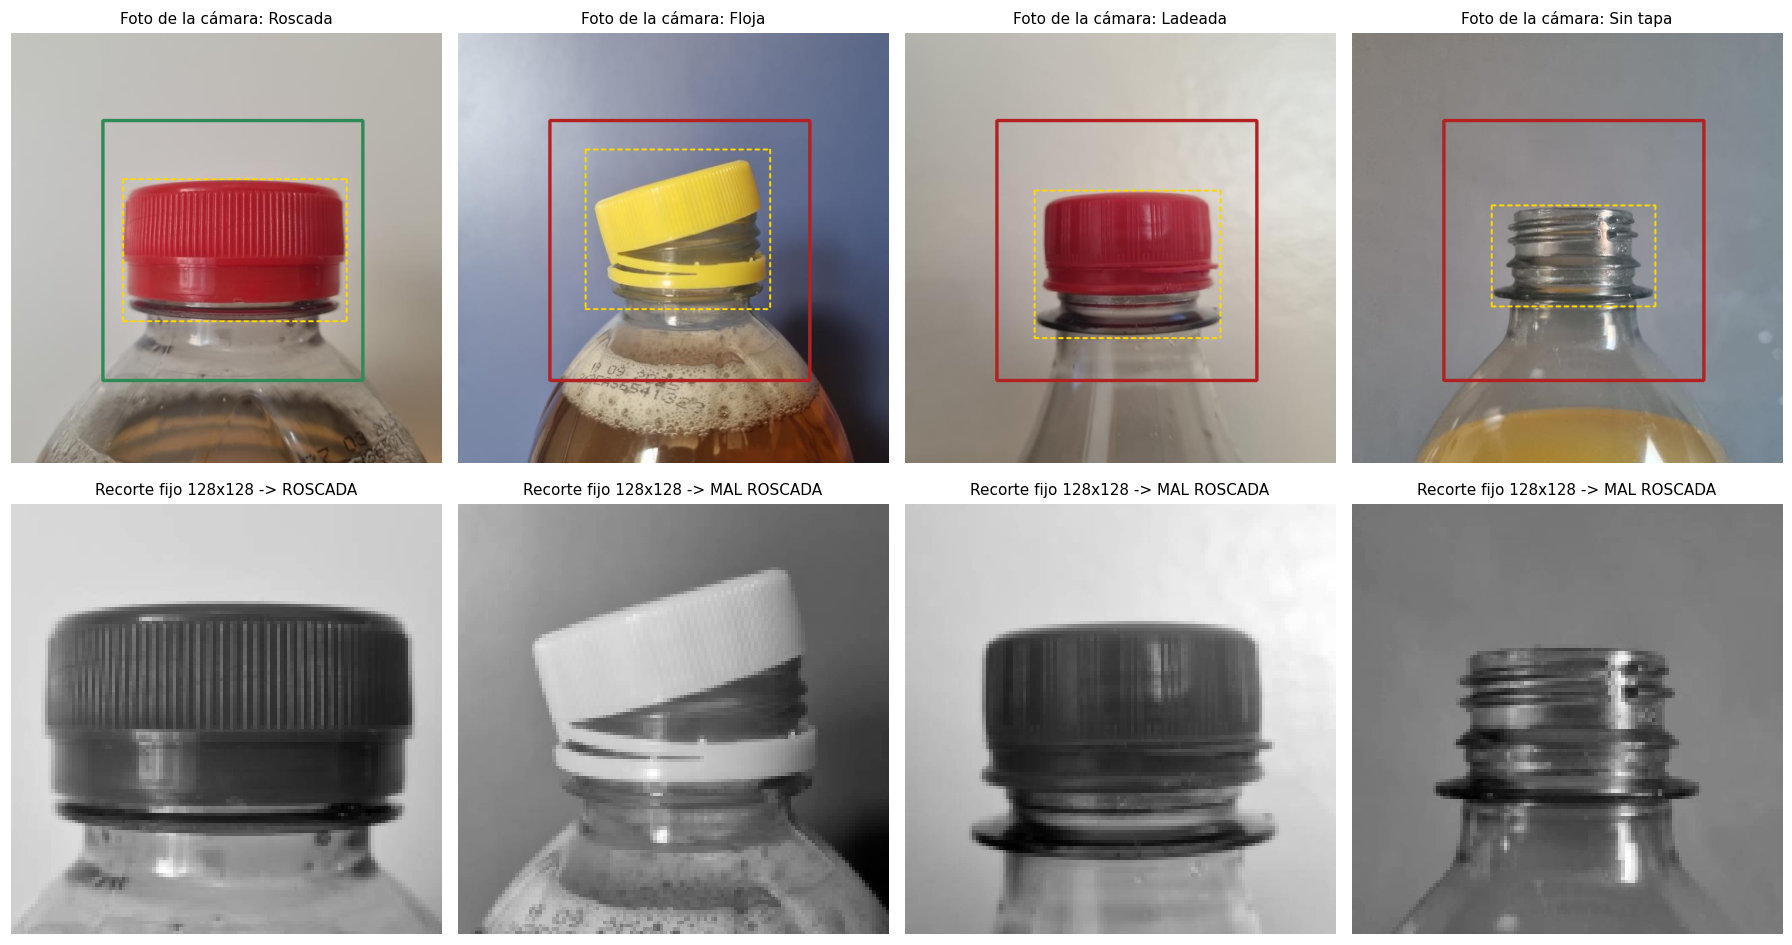

In [5]:
# De la foto de la cámara al recorte: caja anotada (punteada, solo de referencia) y cuadrado fijo que se recorta (ROI)
# Un ejemplo típico de cada tipo: la foto cuya caja tiene la proporción alto/ancho más cercana a la mediana de su tipo
ejemplos_roi = []
for t in MAPA_CLASES:
    proporcion = (info_train['h'] / info_train['w'])[tipo_train == t]
    if len(proporcion):
        ejemplos_roi.append((proporcion - proporcion.median()).abs().idxmin())
fig, axes = plt.subplots(2, len(ejemplos_roi), figsize=(4.1 * len(ejemplos_roi), 8.9))
axes = axes.reshape(2, -1)
for col, i in enumerate(ejemplos_roi):
    fila = info_train.loc[i]
    foto = cv2.cvtColor(cv2.imread(fila['ruta']), cv2.COLOR_BGR2RGB)
    alto, ancho = foto.shape[:2]
    color = (46, 139, 87) if MAPA_CLASES[fila['tipo']] == 0 else (178, 34, 34)
    x0, y0, x1, y1 = cuadro_roi(foto.shape)
    cv2.rectangle(foto, (x0, y0), (x1, y1), color, max(2, ancho // 160))
    bx0, by0 = int((fila['cx'] - fila['w'] / 2) * ancho), int((fila['cy'] - fila['h'] / 2) * alto)
    bx1, by1 = int((fila['cx'] + fila['w'] / 2) * ancho), int((fila['cy'] + fila['h'] / 2) * alto)
    for x in range(bx0, bx1, 12):
        cv2.line(foto, (x, by0), (min(x + 6, bx1), by0), (255, 215, 0), 2)
        cv2.line(foto, (x, by1), (min(x + 6, bx1), by1), (255, 215, 0), 2)
    for y in range(by0, by1, 12):
        cv2.line(foto, (bx0, y), (bx0, min(y + 6, by1)), (255, 215, 0), 2)
        cv2.line(foto, (bx1, y), (bx1, min(y + 6, by1)), (255, 215, 0), 2)
    axes[0, col].imshow(foto)
    axes[0, col].set_title(f"Foto de la cámara: {NOMBRE_TIPO[fila['tipo']]}", fontsize=10)
    axes[1, col].imshow(X_train[i], cmap='gray')
    axes[1, col].set_title(f"Recorte fijo 128x128 -> {CLASES[MAPA_CLASES[fila['tipo']]]}", fontsize=10)
    for ax in axes[:, col]:
        ax.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_FIGURAS, "roi.png"), bbox_inches='tight')
plt.show()

## 3. Extracción de características

Se usan los mismos tres descriptores y parámetros vistos en clase:

| Descriptor | Qué mide | Por qué sirve para revisar el roscado |
|---|---|---|
| **HOG** (9 orientaciones, celdas 8×8, bloques 2×2) | Dirección e intensidad de los bordes en cada zona del recorte | Una tapa floja o ladeada inclina el borde inferior de la tapa y deja ver la rosca en un **lugar concreto**, entre la tapa y el anillo del cuello. HOG conserva esa ubicación |
| **LBP** uniforme (P=8, R=1) | Histograma de micro-patrones de textura | El moleteado de la tapa y los hilos de la rosca tienen texturas distintas |
| **GLCM** (distancias 1 y 3, 4 ángulos, 64 niveles) | Contraste, homogeneidad, energía y correlación entre píxeles vecinos | Resume la textura de todo el recorte en pocos números |

In [6]:
# HOG (Histogram of Oriented Gradients)
def extraer_hog(imagenes):
    hog_features = []
    for img in imagenes:
        features = hog(img, orientations=9, pixels_per_cell=(8, 8),
                       cells_per_block=(2, 2), block_norm='L2-Hys', visualize=False)
        hog_features.append(features)
    return np.array(hog_features)

# LBP (Local Binary Patterns)
def extraer_lbp(imagenes, P=8, R=1):
    lbp_features = []
    for img in imagenes:
        lbp = local_binary_pattern(img, P=P, R=R, method="uniform")
        # Histograma de patrones uniformes (P + 2 valores posibles)
        (hist, _) = np.histogram(lbp.ravel(), bins=np.arange(0, P + 3), range=(0, P + 2))
        hist = hist.astype("float32")
        hist /= (hist.sum() + 1e-7)  # normalización del histograma
        lbp_features.append(hist)
    return np.array(lbp_features)

# GLCM (Gray-Level Co-occurrence Matrix)
def extraer_glcm(imagenes, distances=[1, 3], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4]):
    glcm_features = []
    propiedades = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM']
    for img in imagenes:
        img_q = (img // 4).astype(np.uint8)  # 64 niveles de gris para acelerar el cálculo
        glcm = graycomatrix(img_q, distances=distances, angles=angles, levels=64, symmetric=True, normed=True)
        vector_img = []
        for prop in propiedades:
            vector_img.extend(graycoprops(glcm, prop).ravel())
        glcm_features.append(vector_img)
    return np.array(glcm_features)

In [7]:
# Extracción midiendo el tiempo por imagen (este tiempo también cuenta en la línea de producción)
extractores = {'HOG': extraer_hog, 'LBP': extraer_lbp, 'GLCM': extraer_glcm}
caracteristicas = {}
tiempo_extraccion = {}  # milisegundos por imagen

for nombre, funcion in extractores.items():
    t0 = time.time()
    F_train = funcion(X_train)
    F_test = funcion(X_test)
    tiempo_extraccion[nombre] = 1000 * (time.time() - t0) / (len(X_train) + len(X_test))
    caracteristicas[nombre] = (F_train, F_test)
    print(f"{nombre:5s} -> {F_train.shape[1]:5d} dimensiones | {tiempo_extraccion[nombre]:.2f} ms por imagen")

HOG   ->  8100 dimensiones | 5.48 ms por imagen


LBP   ->    10 dimensiones | 2.12 ms por imagen


GLCM  ->    48 dimensiones | 2.36 ms por imagen


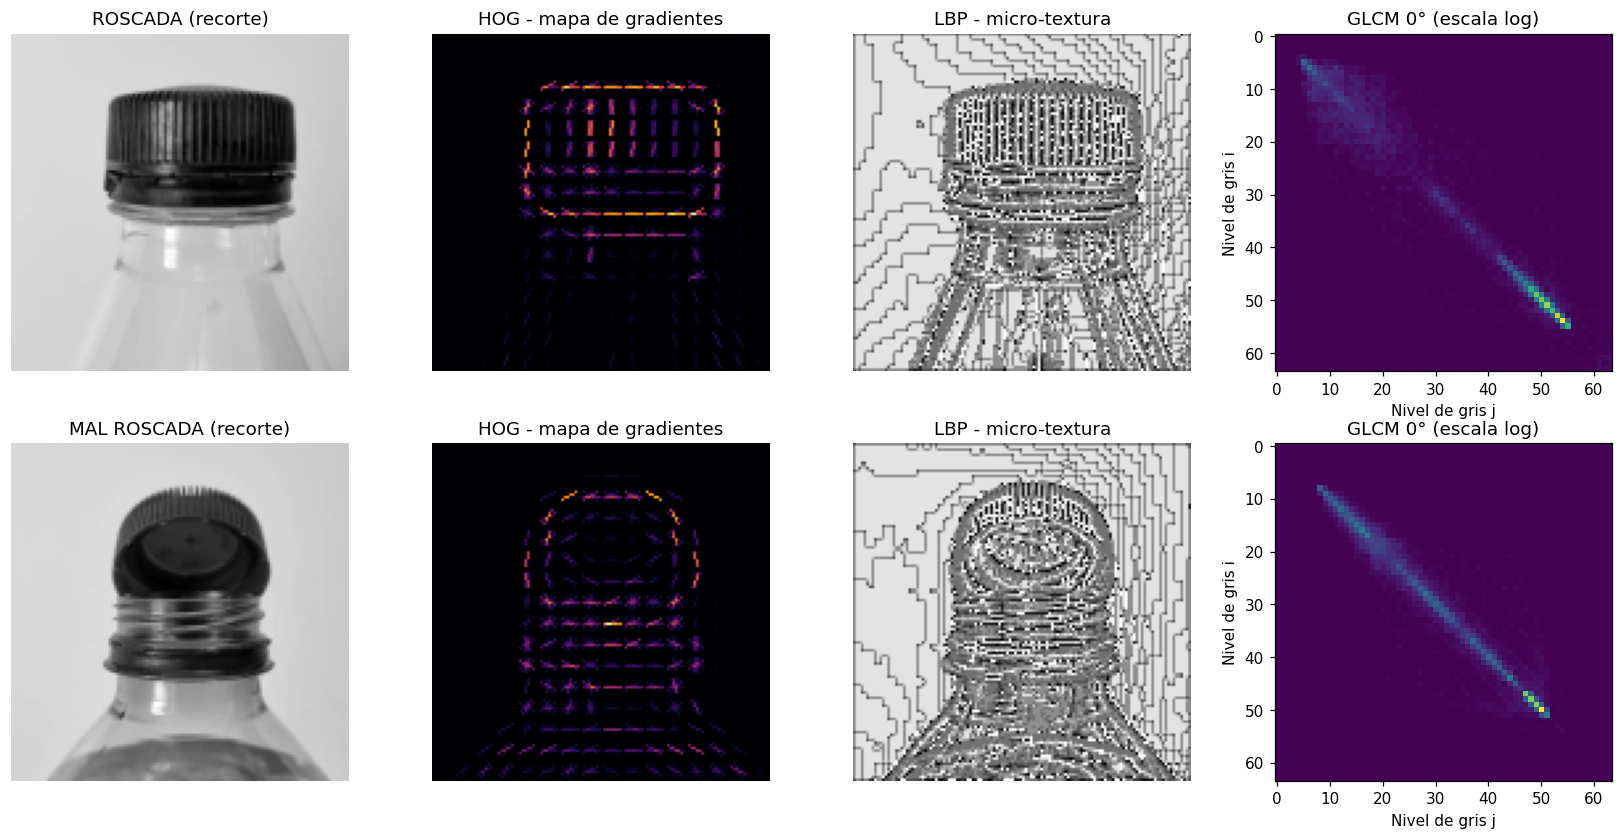

In [8]:
# Visualización de los descriptores sobre una tapa roscada y una mal roscada
idx_ok = np.where(tipo_test == 'good_cap')[0][0]
idx_mal = np.where(tipo_test == 'open_cap')[0][0] if (tipo_test == 'open_cap').any() else np.where(y_test == 1)[0][0]
ejemplos = [('ROSCADA', X_test[idx_ok]), ('MAL ROSCADA', X_test[idx_mal])]

fig, axes = plt.subplots(2, 4, figsize=(15, 7.6))
for fila, (nombre, img) in enumerate(ejemplos):
    _, hog_vis = hog(img, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)
    lbp_vis = local_binary_pattern(img, P=8, R=1, method="uniform")
    glcm_vis = graycomatrix((img // 4).astype(np.uint8), distances=[1], angles=[0], levels=64,
                            symmetric=True, normed=True)[:, :, 0, 0]

    axes[fila, 0].imshow(img, cmap='gray');            axes[fila, 0].set_title(f"{nombre} (recorte)")
    axes[fila, 1].imshow(hog_vis, cmap='inferno');     axes[fila, 1].set_title("HOG - mapa de gradientes")
    axes[fila, 2].imshow(lbp_vis, cmap='gray');        axes[fila, 2].set_title("LBP - micro-textura")
    axes[fila, 3].imshow(np.log1p(1000 * glcm_vis), cmap='viridis')
    axes[fila, 3].set_title("GLCM 0° (escala log)")
    axes[fila, 3].set_xlabel("Nivel de gris j"); axes[fila, 3].set_ylabel("Nivel de gris i")
    for c in range(3):
        axes[fila, c].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_FIGURAS, "descriptores.png"), bbox_inches='tight')
plt.show()

## 4. Normalización Z-score y reducción con PCA

Cada descriptor se normaliza con **Z-score** (media 0, desviación 1) y el `StandardScaler` se ajusta **solo con `train`**. Si se ajustara con todo el dataset, la información de `test` se filtraría al modelo. Luego se arma la **fusión** HOG + LBP + GLCM.

El vector fusionado tiene más de 8.000 dimensiones y casi todas vienen de HOG. Por eso se prueba también una **reducción con PCA**, que conserva el 95 % de la varianza.

In [9]:
conjuntos = {}    # nombre -> (X_train, X_test) ya normalizados
escaladores = {}  # se guardan para usarlos después con botellas nuevas

# 1. Escaladores independientes para cada descriptor
for nombre in ['HOG', 'LBP', 'GLCM']:
    F_train, F_test = caracteristicas[nombre]
    escaladores[nombre] = StandardScaler()
    conjuntos[nombre] = (escaladores[nombre].fit_transform(F_train), escaladores[nombre].transform(F_test))

# 2. Fusión de los tres descriptores y escalado del vector completo
F_train_fusion = np.hstack([caracteristicas[n][0] for n in ['HOG', 'LBP', 'GLCM']])
F_test_fusion = np.hstack([caracteristicas[n][1] for n in ['HOG', 'LBP', 'GLCM']])
scaler_fusion = StandardScaler()
X_train_fusion = scaler_fusion.fit_transform(F_train_fusion)
X_test_fusion = scaler_fusion.transform(F_test_fusion)
conjuntos['Fusión'] = (X_train_fusion, X_test_fusion)

# 3. Reducción con PCA (95 % de la varianza) sobre la fusión normalizada
t0 = time.time()
pca = PCA(n_components=0.95, random_state=SEMILLA)
X_train_pca = pca.fit_transform(X_train_fusion)
X_test_pca = pca.transform(X_test_fusion)
t_pca = time.time() - t0
conjuntos['Fusión + PCA'] = (X_train_pca, X_test_pca)

for nombre, (Xtr, Xte) in conjuntos.items():
    print(f"{nombre:13s} -> Train: {Xtr.shape}, Test: {Xte.shape}")
print(f"\nPCA reduce de {X_train_fusion.shape[1]} a {pca.n_components_} dimensiones "
      f"({100 * pca.n_components_ / X_train_fusion.shape[1]:.1f} %) en {t_pca:.1f} s")

HOG           -> Train: (1994, 8100), Test: (855, 8100)
LBP           -> Train: (1994, 10), Test: (855, 10)
GLCM          -> Train: (1994, 48), Test: (855, 48)
Fusión        -> Train: (1994, 8158), Test: (855, 8158)
Fusión + PCA  -> Train: (1994, 1055), Test: (855, 1055)

PCA reduce de 8158 a 1055 dimensiones (12.9 %) en 9.8 s


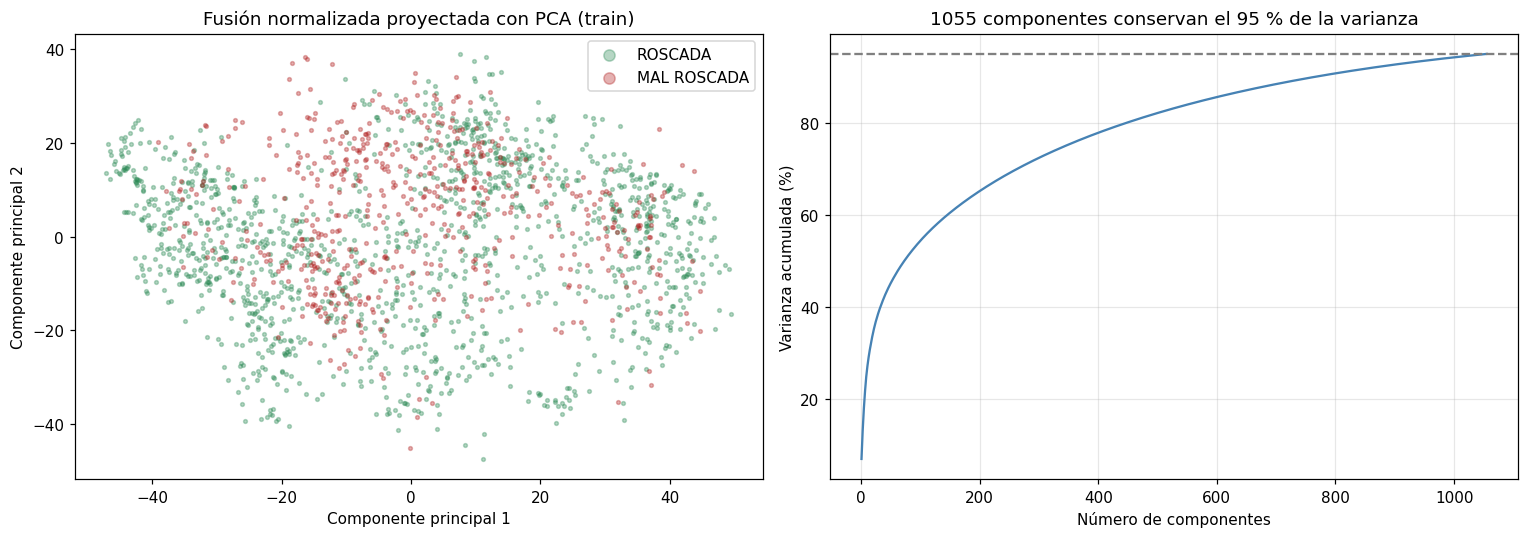

In [10]:
# Proyección en las dos primeras componentes principales y varianza acumulada
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for clase, color in zip([0, 1], ['seagreen', 'firebrick']):
    m = y_train == clase
    axes[0].scatter(X_train_pca[m, 0], X_train_pca[m, 1], s=6, alpha=0.35, c=color, label=CLASES[clase])
axes[0].set_xlabel("Componente principal 1"); axes[0].set_ylabel("Componente principal 2")
axes[0].set_title("Fusión normalizada proyectada con PCA (train)")
axes[0].legend(markerscale=3)

var_acum = np.cumsum(pca.explained_variance_ratio_)
axes[1].plot(np.arange(1, len(var_acum) + 1), 100 * var_acum, color='steelblue')
axes[1].axhline(95, color='gray', linestyle='--')
axes[1].set_xlabel("Número de componentes"); axes[1].set_ylabel("Varianza acumulada (%)")
axes[1].set_title(f"{pca.n_components_} componentes conservan el 95 % de la varianza")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_FIGURAS, "pca.png"), bbox_inches='tight')
plt.show()

## 5. Benchmark de clasificadores

Cada conjunto de características se combina con los tres modelos vistos en clase. La clase positiva es **MAL ROSCADA**, así que:

- **Recall** = fracción de tapas mal roscadas que el sistema atrapa. Es la métrica que más le importa a la embotelladora.
- **Precision** = de las botellas que el sistema rechaza, cuántas sí tenían la tapa mal.
- El tiempo de predicción se reporta **por botella**.

En `train` hay 2,4 tapas roscadas por cada tapa mal roscada, y dejar escapar una tapa mala le cuesta a la planta mucho más que apartar una buena. Por eso SVM y Random Forest se entrenan con `class_weight='balanced'`, que le da más peso a cada error sobre la clase minoritaria. k-NN no tiene ese parámetro y se deja igual que en clase.

In [11]:
models = {
    'k-NN (k=5)': KNeighborsClassifier(n_neighbors=5, metric='euclidean'),
    'SVM (RBF)': SVC(kernel='rbf', C=1.0, gamma='scale', class_weight='balanced', random_state=SEMILLA),
    'Random Forest': RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=SEMILLA, n_jobs=-1)
}

results = []
modelos_entrenados = {}
predicciones = {}
print("Iniciando benchmark de modelos y descriptores...\n")

for feat_name, (Xtr, Xte) in conjuntos.items():
    for model_name, base in models.items():
        model = clone(base)

        t0 = time.time()
        model.fit(Xtr, y_train)          # entrenamiento
        t_fit = time.time() - t0

        t0 = time.time()
        y_pred = model.predict(Xte)      # predicción
        t_pred = 1000 * (time.time() - t0) / len(Xte)

        modelos_entrenados[(feat_name, model_name)] = model
        predicciones[(feat_name, model_name)] = y_pred
        results.append({
            'Descriptor': feat_name,
            'Modelo': model_name,
            'Dimensiones': Xtr.shape[1],
            'Accuracy': accuracy_score(y_test, y_pred),
            'Precision': precision_score(y_test, y_pred, zero_division=0),
            'Recall': recall_score(y_test, y_pred, zero_division=0),
            'F1-Score': f1_score(y_test, y_pred, zero_division=0),
            'Entrenamiento (s)': t_fit,
            'Predicción (ms/botella)': t_pred
        })
        print(f"{feat_name:13s} | {model_name:13s} | F1 = {results[-1]['F1-Score']:.4f}")

df_results = pd.DataFrame(results)

Iniciando benchmark de modelos y descriptores...



HOG           | k-NN (k=5)    | F1 = 0.9067


HOG           | SVM (RBF)     | F1 = 0.9402


HOG           | Random Forest | F1 = 0.8287
LBP           | k-NN (k=5)    | F1 = 0.7018


LBP           | SVM (RBF)     | F1 = 0.6939


LBP           | Random Forest | F1 = 0.7127
GLCM          | k-NN (k=5)    | F1 = 0.7900


... (3 outputs left out)

Fusión        | SVM (RBF)     | F1 = 0.9400


Fusión        | Random Forest | F1 = 0.8184
Fusión + PCA  | k-NN (k=5)    | F1 = 0.9134


Fusión + PCA  | SVM (RBF)     | F1 = 0.9419


Fusión + PCA  | Random Forest | F1 = 0.3003


In [12]:
print("=" * 100)
print("TABLA CONSOLIDADA DE BENCHMARK (TAPAS: ROSCADA VS MAL ROSCADA) - conjunto test")
print("=" * 100)
display(df_results.style.format({'Accuracy': '{:.4f}', 'Precision': '{:.4f}', 'Recall': '{:.4f}',
                                 'F1-Score': '{:.4f}', 'Entrenamiento (s)': '{:.2f}',
                                 'Predicción (ms/botella)': '{:.3f}'})
                        .background_gradient(subset=['F1-Score', 'Recall'], cmap='Greens'))

TABLA CONSOLIDADA DE BENCHMARK (TAPAS: ROSCADA VS MAL ROSCADA) - conjunto test


,Descriptor,Modelo,Dimensiones,Accuracy,Precision,Recall,F1-Score,Entrenamiento (s),Predicción (ms/botella)
0,HOG,k-NN (k=5),8100,0.9497,0.9858,0.8394,0.9067,0.02,0.604
1,HOG,SVM (RBF),8100,0.9661,0.9661,0.9157,0.9402,16.61,10.114
2,HOG,Random Forest,8100,0.9135,0.9781,0.7189,0.8287,3.49,0.052
3,LBP,k-NN (k=5),10,0.8480,0.8182,0.6145,0.7018,0.00,0.050
4,LBP,SVM (RBF),10,0.7895,0.6018,0.8193,0.6939,0.09,0.082
5,LBP,Random Forest,10,0.8444,0.7710,0.6627,0.7127,0.21,0.069
6,GLCM,k-NN (k=5),48,0.8924,0.9153,0.6948,0.7900,0.00,0.057
7,GLCM,SVM (RBF),48,0.9228,0.8828,0.8474,0.8648,0.11,0.081
8,GLCM,Random Forest,48,0.9146,0.9783,0.7229,0.8314,0.28,0.036
9,Fusión,k-NN (k=5),8158,0.9520,0.9906,0.8434,0.9111,0.02,0.381


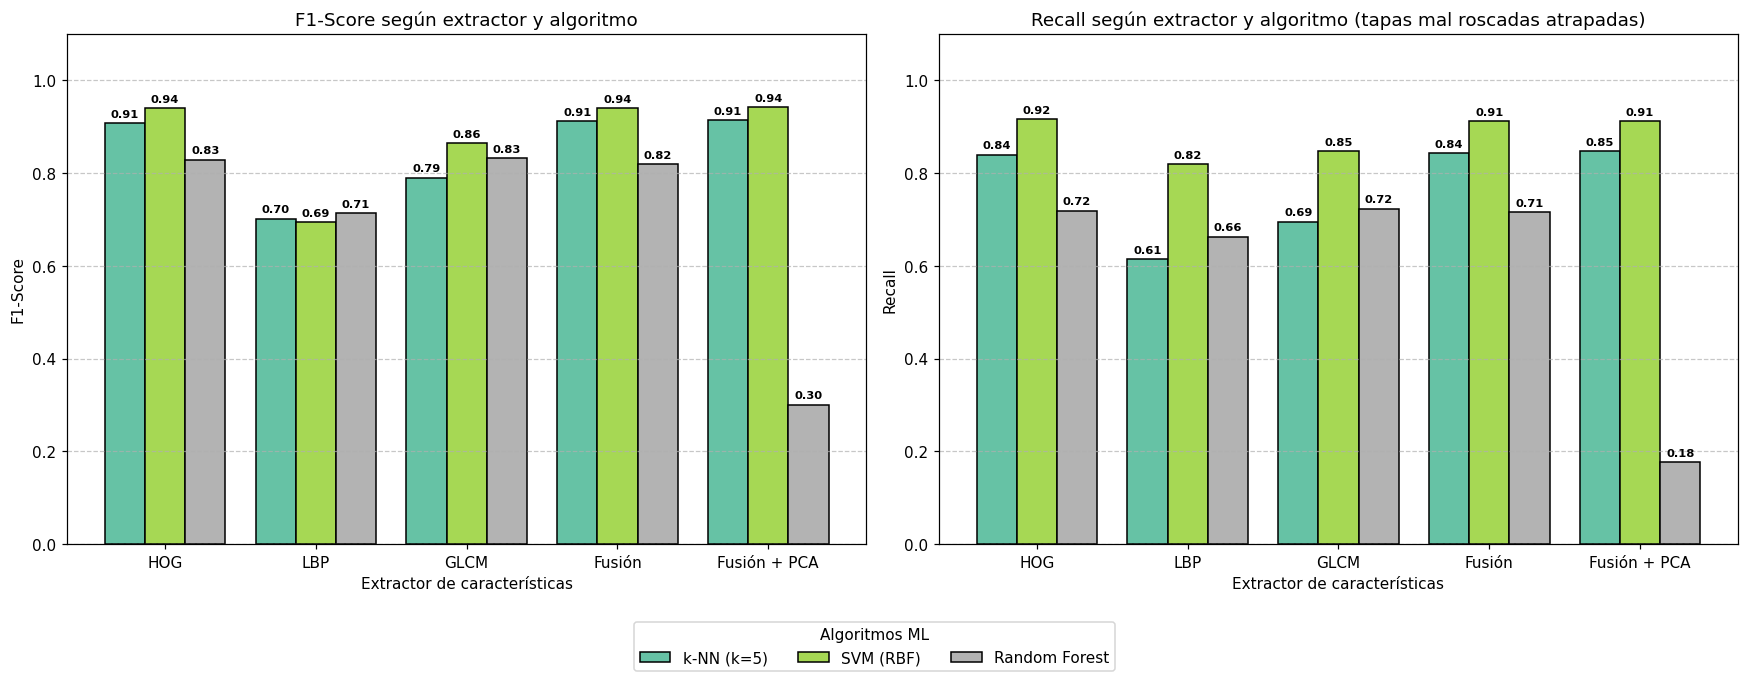

In [13]:
orden = list(conjuntos.keys())
fig, axes = plt.subplots(1, 2, figsize=(16, 6.2))
for ax, metrica in zip(axes, ['F1-Score', 'Recall']):
    df_pivot = df_results.pivot(index='Descriptor', columns='Modelo', values=metrica).loc[orden, list(models.keys())]
    df_pivot.plot(kind='bar', ax=ax, colormap='Set2', edgecolor='black', width=0.8, legend=False)
    ax.set_title(f"{metrica} según extractor y algoritmo" + (" (tapas mal roscadas atrapadas)" if metrica == 'Recall' else ""),
                 fontsize=12)
    ax.set_ylabel(metrica); ax.set_xlabel("Extractor de características")
    ax.set_ylim(0, 1.1)
    ax.tick_params(axis='x', rotation=0)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    for p in ax.patches:
        if p.get_height() > 0:
            ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha='center', va='center', xytext=(0, 6), textcoords='offset points',
                        fontsize=7.5, fontweight='bold')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Algoritmos ML", loc='lower center', ncol=3)
plt.tight_layout(rect=[0, 0.1, 1, 1])
plt.savefig(os.path.join(CARPETA_FIGURAS, "benchmark.png"), bbox_inches='tight')
plt.show()

## 6. Modelo elegido y métricas de negocio

Se elige la combinación con mejor **F1-Score**. Si hay empate, gana la que tenga mayor recall y luego la más rápida. A la embotelladora no le importa el accuracy en abstracto, sino dos errores concretos:

- **Tapa mal roscada que se escapa** (falso negativo): la botella llega al cliente y se derrama, pierde el gas o se contamina. Genera reclamos, devoluciones y pérdida de confianza.
- **Falso rechazo** (falso positivo): una botella bien tapada se aparta. Cuesta revisarla a mano o volver a taparla.

,Valor
Sistema elegido,Fusión + PCA + SVM (RBF)
Tapas mal roscadas detectadas (recall),91.16 % (227 de 249)
Tapas mal roscadas que se escapan,8.84 % (22 botellas)
Botellas bien tapadas rechazadas,0.99 % (6 de 606)
Exactitud global,96.73 %
"Tiempo de cálculo por botella (CPU, sin GPU)",11.5 ms
Capacidad de cómputo (sin contar la cámara),"313,513 botellas/hora"


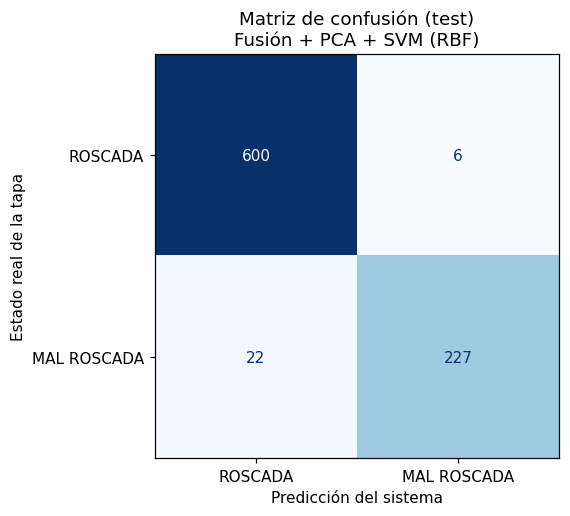

In [14]:
mejor = df_results.sort_values(['F1-Score', 'Recall', 'Predicción (ms/botella)'],
                               ascending=[False, False, True]).iloc[0]
desc_elegido, modelo_elegido = mejor['Descriptor'], mejor['Modelo']
modelo = modelos_entrenados[(desc_elegido, modelo_elegido)]
y_pred = modelo.predict(conjuntos[desc_elegido][1])
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

# Tiempo total por botella = extraer descriptores + normalizar/reducir + predecir
if desc_elegido in ('Fusión', 'Fusión + PCA'):
    t_extr = sum(tiempo_extraccion.values())
else:
    t_extr = tiempo_extraccion[desc_elegido]
t_total = t_extr + mejor['Predicción (ms/botella)']

negocio = pd.DataFrame({'Valor': [
    f"{desc_elegido} + {modelo_elegido}",
    f"{100 * tp / (tp + fn):.2f} %  ({tp} de {tp + fn})",
    f"{100 * fn / (tp + fn):.2f} %  ({fn} botellas)",
    f"{100 * fp / (fp + tn):.2f} %  ({fp} de {fp + tn})",
    f"{100 * (tp + tn) / len(y_test):.2f} %",
    f"{t_total:.1f} ms",
    f"{3600 * 1000 / t_total:,.0f} botellas/hora"
]}, index=['Sistema elegido', 'Tapas mal roscadas detectadas (recall)', 'Tapas mal roscadas que se escapan',
           'Botellas bien tapadas rechazadas', 'Exactitud global', 'Tiempo de cálculo por botella (CPU, sin GPU)',
           'Capacidad de cómputo (sin contar la cámara)'])
display(negocio)

fig, ax = plt.subplots(figsize=(5.6, 4.8))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=CLASES).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f"Matriz de confusión (test)\n{desc_elegido} + {modelo_elegido}")
ax.set_xlabel("Predicción del sistema"); ax.set_ylabel("Estado real de la tapa")
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_FIGURAS, "matriz_confusion.png"), bbox_inches='tight')
plt.show()

In [15]:
# ¿Qué tipo de falla atrapa el sistema elegido?
por_tipo = []
for t in MAPA_CLASES:
    m = tipo_test == t
    if m.any():
        correctas = int((y_pred[m] == MAPA_CLASES[t]).sum())
        por_tipo.append({'Tipo de tapa': NOMBRE_TIPO[t], 'Veredicto correcto': CLASES[MAPA_CLASES[t]],
                         'Botellas en test': int(m.sum()), 'Clasificadas bien': correctas,
                         'Acierto (%)': round(100 * correctas / m.sum(), 1)})
display(pd.DataFrame(por_tipo).set_index('Tipo de tapa'))

,Veredicto correcto,Botellas en test,Clasificadas bien,Acierto (%)
Tipo de tapa,,,,
Roscada,ROSCADA,606,600,99.0
Floja,MAL ROSCADA,94,91,96.8
Ladeada,MAL ROSCADA,74,56,75.7
Sin tapa,MAL ROSCADA,81,80,98.8


### Impacto económico (ejemplo con supuestos editables)

Los valores de esta celda son **supuestos ilustrativos** para una embotelladora mediana y se pueden ajustar a cada cliente. Las tasas de error de TapaCheck **sí** salen de la matriz de confusión anterior.

La referencia de inspección manual viene de un estudio de Sandia National Laboratories (See, J. E., 2015, *Visual Inspection Reliability for Precision Manufactured Parts*, Human Factors 57(8), 1427–1442): el promedio de la industria detecta cerca del **80 %** de los defectos. En una línea que pasa miles de botellas por hora la revisión es todavía más difícil, así que ese 80 % es una referencia generosa para el operario.

In [16]:
# --- Supuestos (editables) ---
BOTELLAS_HORA = 2_400              # velocidad de la línea de embotellado
HORAS_DIA = 16                     # dos turnos de 8 horas
DIAS_MES = 26
TASA_MAL_ROSCADA = 0.005           # 0,5 % de las botellas sale con la tapa floja, ladeada o sin tapa
COSTO_ESCAPE = 12_000              # COP: botella mal tapada que llega al cliente (producto, reclamo, devolución y flete)
COSTO_FALSO_RECHAZO = 500          # COP: revisar a mano o volver a tapar una botella buena apartada por error
DETECCION_MANUAL = 0.80            # promedio de la industria: ~80 % de defectos detectados (See, 2015)
FALSO_RECHAZO_MANUAL = 0.01        # botellas buenas que el operario aparta por error

BOTELLAS_DIA = BOTELLAS_HORA * HORAS_DIA

def costo_mensual(deteccion, falso_rechazo):
    malas = BOTELLAS_DIA * TASA_MAL_ROSCADA
    buenas = BOTELLAS_DIA - malas
    escapes = malas * (1 - deteccion)
    rechazos = buenas * falso_rechazo
    return DIAS_MES * escapes, DIAS_MES * rechazos, DIAS_MES * (escapes * COSTO_ESCAPE + rechazos * COSTO_FALSO_RECHAZO)

det_tc, fr_tc = tp / (tp + fn), fp / (fp + tn)
esc_m, rech_m, costo_m = costo_mensual(DETECCION_MANUAL, FALSO_RECHAZO_MANUAL)
esc_t, rech_t, costo_t = costo_mensual(det_tc, fr_tc)

impacto = pd.DataFrame({
    'Inspección manual': [f"{esc_m:,.0f}", f"{rech_m:,.0f}", f"${costo_m:,.0f}", "1 operario por turno"],
    'TapaCheck': [f"{esc_t:,.0f}", f"{rech_t:,.0f}", f"${costo_t:,.0f}",
                  f"{3600 * 1000 / t_total / BOTELLAS_HORA:,.0f} veces la velocidad de la línea"]
}, index=['Botellas mal tapadas que llegan al cliente (mes)', 'Botellas buenas apartadas por error (mes)',
          'Costo mensual de errores (COP)', 'Capacidad de revisión'])
print(f"Línea de ejemplo: {BOTELLAS_DIA:,} botellas al día, {BOTELLAS_DIA * TASA_MAL_ROSCADA:,.0f} con la tapa mal")
display(impacto)
print(f"Ahorro estimado: ${costo_m - costo_t:,.0f} COP al mes "
      f"({100 * (costo_m - costo_t) / costo_m:.0f} % menos costo por errores de tapado)")

Línea de ejemplo: 38,400 botellas al día, 192 con la tapa mal


,Inspección manual,TapaCheck
Botellas mal tapadas que llegan al cliente (mes),998,441
Botellas buenas apartadas por error (mes),"9,934","9,836"
Costo mensual de errores (COP),"$16,947,840","$10,210,584"
Capacidad de revisión,1 operario por turno,131 veces la velocidad de la línea


Ahorro estimado: $6,737,256 COP al mes (40 % menos costo por errores de tapado)


### Ranking de negocio: ¿qué combinación le cuesta menos a la embotelladora?

El F1-Score trata igual los dos errores, pero a la planta no le cuestan lo mismo: una botella mal tapada que llega al cliente vale mucho más que una revisión manual. Por eso se ordenan las 15 combinaciones según el **costo mensual de errores**, con los mismos supuestos de la celda anterior.

In [17]:
ranking = []
for (feat_name, model_name), pred in predicciones.items():
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, pred).ravel()
    ranking.append({'Descriptor': feat_name, 'Modelo': model_name,
                    f'Mal roscadas que se escapan (de {tp_ + fn_})': fn_,
                    f'Bien tapadas rechazadas (de {tn_ + fp_})': fp_,
                    'Costo mensual de errores (COP)': costo_mensual(tp_ / (tp_ + fn_), fp_ / (fp_ + tn_))[2]})
df_ranking = pd.DataFrame(ranking).sort_values('Costo mensual de errores (COP)').reset_index(drop=True)
df_ranking.index += 1
display(df_ranking.style.format({'Costo mensual de errores (COP)': '${:,.0f}'})
                        .background_gradient(subset=['Costo mensual de errores (COP)'], cmap='Reds'))

,Descriptor,Modelo,Mal roscadas que se escapan (de 249),Bien tapadas rechazadas (de 606),Costo mensual de errores (COP)
1,Fusión + PCA,SVM (RBF),22,6,"$10,210,584"
2,Fusión + PCA,k-NN (k=5),38,2,"$10,781,263"
3,Fusión,k-NN (k=5),39,2,"$11,021,841"
4,Fusión,SVM (RBF),22,7,"$11,030,228"
5,HOG,SVM (RBF),21,8,"$11,609,293"
6,HOG,k-NN (k=5),40,3,"$12,082,063"
7,GLCM,Random Forest,69,4,"$19,878,478"
8,HOG,Random Forest,70,4,"$20,119,056"
9,Fusión,Random Forest,71,8,"$23,638,209"
10,GLCM,k-NN (k=5),76,16,"$31,398,249"


### Prueba extra: días de captura que el modelo nunca vio

Cada archivo lleva en el nombre la fecha en que se tomó la foto. La tabla de abajo muestra que casi todas las tapas roscadas se fotografiaron el 29 y el 30 de octubre, y las mal roscadas entre el 31 de octubre y el 4 de noviembre. Entonces el modelo podría estar aprendiendo a reconocer **el día** (la luz, el fondo, las botellas de esa sesión) en lugar del estado de la tapa.

Para medir ese riesgo se entrena otra vez el sistema elegido, con el mismo descriptor y el mismo modelo, pero separando por días completos:

- **Entrenamiento:** tapas roscadas del 29 de octubre y mal roscadas del 31 de octubre y del 4 de noviembre.
- **Prueba:** tapas roscadas del 30 de octubre y mal roscadas del 1 de noviembre. Ninguna foto de esos días se usa para entrenar.

In [18]:
def dia_de(ruta):
    # Los nombres de archivo empiezan por la fecha de captura: 20241030_124240_jpg.rf....
    return os.path.basename(ruta)[:8]

info_todo = pd.concat([info_train, info_test], ignore_index=True)
dias = info_todo['ruta'].map(dia_de).to_numpy()
y_todo = np.concatenate([y_train, y_test])
tabla_dias = pd.crosstab(dias, info_todo['tipo'].map(NOMBRE_TIPO))
tabla_dias.index.name, tabla_dias.columns.name = 'Día de captura', None
display(tabla_dias)

# Mismo pipeline que el sistema elegido: Z-score (+ PCA si aplica) + modelo, ajustado solo con los días de entrenamiento
F_todo = {n: np.vstack(caracteristicas[n]) for n in ['HOG', 'LBP', 'GLCM']}
if desc_elegido in ('Fusión', 'Fusión + PCA'):
    F_dias = np.hstack([F_todo[n] for n in ['HOG', 'LBP', 'GLCM']])
else:
    F_dias = F_todo[desc_elegido]
pasos = [StandardScaler()]
if desc_elegido == 'Fusión + PCA':
    pasos.append(PCA(n_components=0.95, random_state=SEMILLA))
sistema_dias = make_pipeline(*pasos, clone(models[modelo_elegido]))

en_train = ((y_todo == 0) & np.isin(dias, ['20241029'])) | ((y_todo == 1) & np.isin(dias, ['20241031', '20241104']))
en_prueba = ((y_todo == 0) & np.isin(dias, ['20241030'])) | ((y_todo == 1) & np.isin(dias, ['20241101']))

if en_train.any() and en_prueba.any():
    sistema_dias.fit(F_dias[en_train], y_todo[en_train])
    pred_dias = sistema_dias.predict(F_dias[en_prueba])
    filas_cmp = []
    for nombre, real, pred in [('Partición de Roboflow (fotos al azar)', y_test, y_pred),
                               ('Días nunca vistos', y_todo[en_prueba], pred_dias)]:
        tn_, fp_, fn_, tp_ = confusion_matrix(real, pred, labels=[0, 1]).ravel()
        filas_cmp.append({'Prueba': nombre, 'Botellas': len(real),
                          'Mal roscadas detectadas (recall)': f"{100 * tp_ / (tp_ + fn_):.1f} %  ({tp_} de {tp_ + fn_})",
                          'Bien tapadas rechazadas': f"{100 * fp_ / (fp_ + tn_):.1f} %  ({fp_} de {fp_ + tn_})",
                          'Exactitud': f"{100 * (tp_ + tn_) / len(real):.1f} %",
                          'F1-Score': round(f1_score(real, pred), 4)})
    print(f"Sistema: {desc_elegido} + {modelo_elegido} | entrenamiento: {en_train.sum()} fotos, prueba: {en_prueba.sum()} fotos")
    display(pd.DataFrame(filas_cmp).set_index('Prueba'))
else:
    print("Esta versión del dataset no tiene los días esperados; se omite la prueba por días.")

,Floja,Ladeada,Roscada,Sin tapa
Día de captura,,,,
20241029,0,0,1556,0
20241030,0,0,463,0
20241031,77,51,0,76
20241101,119,34,0,77
20241104,115,163,1,117


Sistema: Fusión + PCA + SVM (RBF) | entrenamiento: 2155 fotos, prueba: 693 fotos


,Botellas,Mal roscadas detectadas (recall),Bien tapadas rechazadas,Exactitud,F1-Score
Prueba,,,,,
Partición de Roboflow (fotos al azar),855,91.2 % (227 de 249),1.0 % (6 de 606),96.7 %,0.9419
Días nunca vistos,693,77.4 % (178 de 230),6.3 % (29 de 463),88.3 %,0.8146


## 7. Demo del producto: `inspeccionar()`

Esto es lo que el cliente instala en su línea: una función que recibe la foto del cuello de la botella y responde **ROSCADA** o **MAL ROSCADA** en milisegundos. Nadie tiene que marcar la tapa, porque usa el mismo recorte fijo de la cámara. El pipeline completo (recorte, descriptores, normalización, PCA si aplica y modelo) se guarda en un solo archivo con `joblib`.

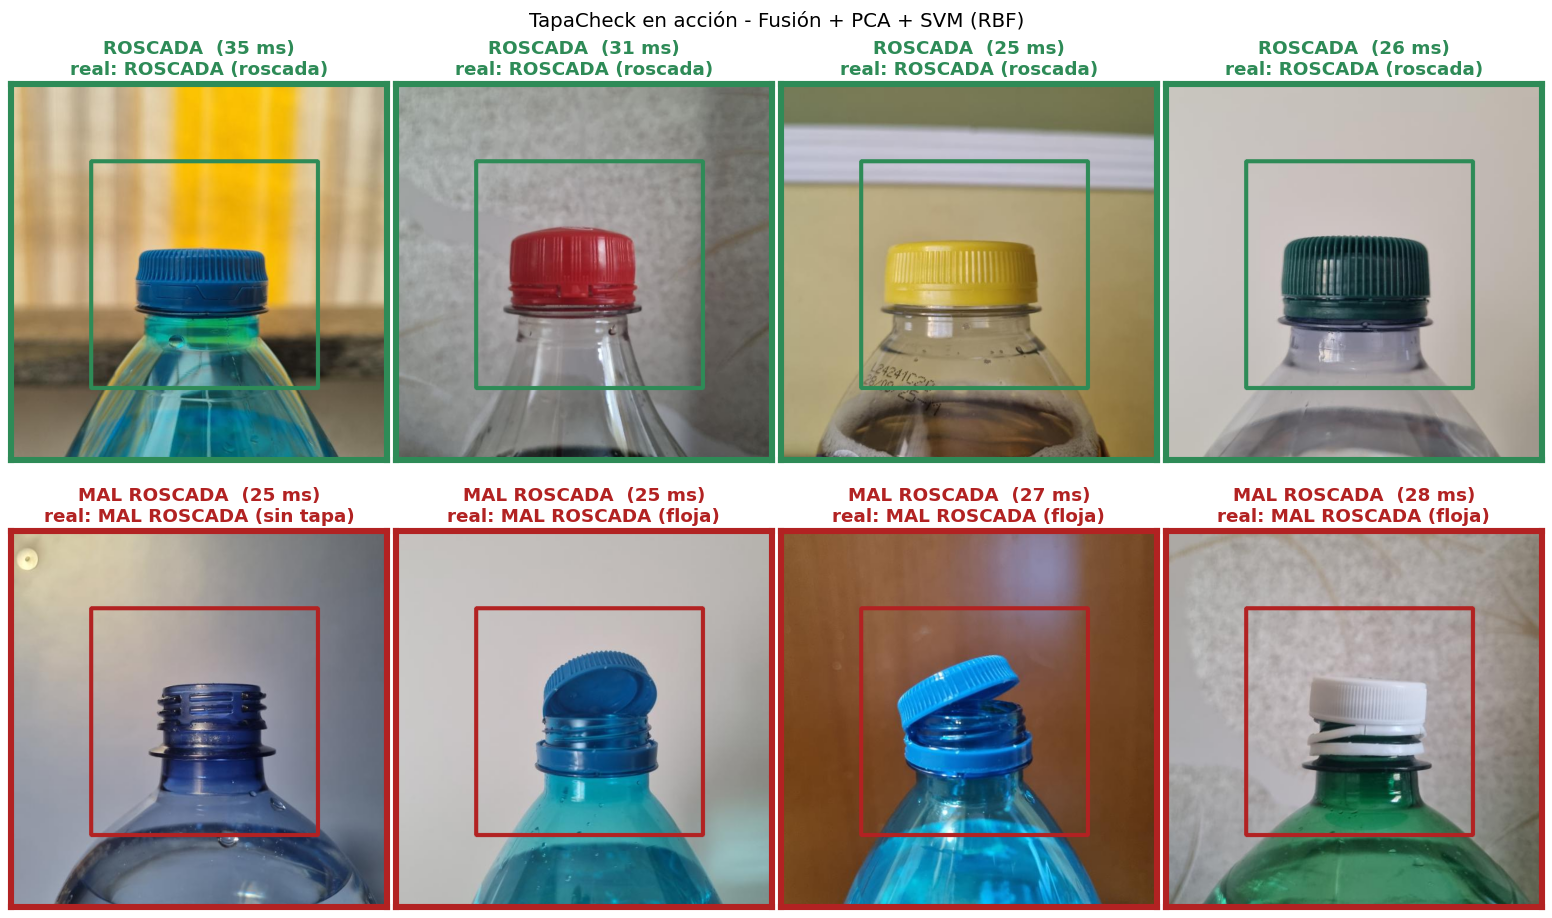

In [19]:
def vector_de(imagenes, descriptor):
    # Extrae y normaliza las características que usa el modelo elegido
    if descriptor in ('HOG', 'LBP', 'GLCM'):
        return escaladores[descriptor].transform(extractores[descriptor](imagenes))
    F = np.hstack([extraer_hog(imagenes), extraer_lbp(imagenes), extraer_glcm(imagenes)])
    X = scaler_fusion.transform(F)
    return pca.transform(X) if descriptor == 'Fusión + PCA' else X

def inspeccionar(ruta_imagen):
    # Recibe solo la foto de la cámara: recorte fijo -> descriptores -> modelo
    t0 = time.time()
    gris = cv2.imread(ruta_imagen, cv2.IMREAD_GRAYSCALE)
    pred = modelo.predict(vector_de(np.array([recortar_tapa(gris)]), desc_elegido))[0]
    return CLASES[pred], 1000 * (time.time() - t0)

# Prueba con fotos de test, leídas directamente desde el disco: 4 bien tapadas y 4 mal tapadas
rng = np.random.default_rng(7)
filas_demo = [i for clase in [0, 1] for i in rng.choice(np.where(y_test == clase)[0], 4, replace=False)]

fig, axes = plt.subplots(2, 4, figsize=(14, 8.4), constrained_layout=True)
for ax, i in zip(axes.ravel(), filas_demo):
    fila = info_test.loc[i]
    pred, ms = inspeccionar(fila['ruta'])
    foto = cv2.cvtColor(cv2.imread(fila['ruta']), cv2.COLOR_BGR2RGB)
    color = (46, 139, 87) if pred == 'ROSCADA' else (178, 34, 34)
    x0, y0, x1, y1 = cuadro_roi(foto.shape)
    cv2.rectangle(foto, (x0, y0), (x1, y1), color, max(3, foto.shape[1] // 120))
    ax.imshow(foto)
    ax.set_title(f"{pred}  ({ms:.0f} ms)\nreal: {CLASES[MAPA_CLASES[fila['tipo']]]} ({NOMBRE_TIPO[fila['tipo']].lower()})",
                 fontweight='bold', color='seagreen' if pred == 'ROSCADA' else 'firebrick')
    for borde in ax.spines.values():
        borde.set_edgecolor('seagreen' if pred == 'ROSCADA' else 'firebrick'); borde.set_linewidth(4)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle(f"TapaCheck en acción - {desc_elegido} + {modelo_elegido}", fontsize=13)
plt.savefig(os.path.join(CARPETA_FIGURAS, "demo.png"), bbox_inches='tight')
plt.show()

In [20]:
# Guardado del pipeline entrenado (recorte, descriptor, escaladores, PCA y modelo)
ruta_modelo = os.path.join(CARPETA_MODELOS, "tapacheck.joblib")
joblib.dump({'descriptor': desc_elegido, 'modelo': modelo, 'escaladores': escaladores,
             'scaler_fusion': scaler_fusion, 'pca': pca, 'tamano': TAMANO, 'roi': ROI,
             'clases': CLASES, 'mapa_clases': MAPA_CLASES, 'nombres': nombres},
            ruta_modelo, compress=3)
print(f"Pipeline guardado en {ruta_modelo} ({os.path.getsize(ruta_modelo) / 1e6:.1f} MB)")

Pipeline guardado en modelos\tapacheck.joblib (76.5 MB)


## 8. Conclusiones

1. **TapaCheck funciona con visión artificial clásica.** Con el recorte fijo del cuello, la fusión HOG + LBP + GLCM, Z-score, PCA y SVM, el sistema clasifica bien el **96,7 %** de las 855 botellas de prueba. Atrapa el **91,2 %** de las tapas mal roscadas (227 de 249) y aparta por error solo el **1,0 %** de las bien tapadas (6 de 606). Cada botella toma unos 12 ms de cálculo en CPU, sin GPU (unos 25 ms foto por foto en la demo, contando la lectura de la imagen), así que un solo computador revisa decenas de veces más botellas de las que pasa una línea de 2.400 por hora.

2. **¿Por qué HOG y no GLCM?** Una tapa mal roscada se reconoce por la forma y por *dónde* están los bordes: la tapa queda más alta o inclinada, y se ve la rosca entre la tapa y el anillo del cuello. HOG mide los bordes zona por zona y conserva esa ubicación: con SVM llega a una F1 de 0,940 y deja escapar 21 de 249 tapas malas. GLCM resume la textura de todo el recorte en 48 números y pierde la ubicación: con el mismo SVM deja escapar 38 y además aparta 28 botellas buenas (HOG aparta 8). LBP, con un histograma global, se queda en una F1 de 0,69 a 0,71.

3. **La fusión con PCA es la versión que va a producción.** Sumar LBP y GLCM a HOG casi no cambia la F1, porque HOG aporta 8.100 de las 8.158 dimensiones. PCA reduce el vector a 1.055 dimensiones, mantiene la F1 (0,942, la mejor de las 15 combinaciones) y hace que SVM entrene y prediga unas 8 veces más rápido que con la fusión completa. Random Forest, en cambio, falla con las componentes de PCA (F1 0,30): la información útil queda repartida en muchas componentes y cada árbol solo mira unas pocas al azar. SVM y k-NN usan todas las componentes a la vez y no sufren ese problema.

4. **Métricas de negocio.** En la línea de ejemplo (2.400 botellas por hora, dos turnos y 0,5 % de tapas mal puestas), las botellas mal tapadas que llegan al cliente bajan de 998 a 441 al mes, y el costo de los errores de tapado baja de unos 16,9 a unos 10,2 millones de pesos al mes (**−40 %**). El ranking por costo elige la misma combinación que el F1-Score.

5. **Limitaciones.**
   - Las tapas **ladeadas** son el caso difícil: el sistema atrapa 3 de cada 4 (56 de 74). Las tapas flojas y las botellas sin tapa casi nunca se escapan (97 % y 99 %).
   - Con **días de captura que el modelo nunca vio**, el recall baja a 77,4 % y los falsos rechazos suben a 6,3 %. Parte del buen resultado con fotos al azar viene de las condiciones de cada sesión de fotos (luz, fondo, botellas). En una línea real la cámara, la luz y el fondo son fijos, lo que juega a favor, pero hay que comprobarlo con fotos del cliente.
   - El recorte fijo supone que la tapa siempre cae en el mismo cuadro, es decir, una cámara fija y un sensor que dispara la foto.

6. **Siguiente paso.** Un piloto en una embotelladora aliada: cámara fija con luz controlada después de la roscadora, dos semanas tomando fotos de su línea para re-entrenar el modelo y dos semanas más midiendo recall y falsos rechazos frente al operario.